# 05 · Validación y evaluación

Este notebook corresponde a los **apartados 4.4 y 4.5** de la memoria. Cada sección lleva el número del apartado al que respalda, y cada tabla o figura se imprime con el mismo número que tiene en la memoria.

| | |
|---|---|
| **Entrada** | `results/03_features_all.csv`, `results/04_cv_fold_scores.csv` y los modelos de `results/models/` (notebook 04) |
| **Funciones** | `src/models.py` |
| **Salida** | tablas y figuras de evaluación en `results/` |

## 0. Configuración

1. Importa las bibliotecas y las funciones de `src/models.py`.
2. Lee la tabla de características y separa los dos conjuntos, igual que en el notebook 04.
3. Carga los seis modelos guardados en el apartado 4.3.4, ya entrenados con las 618 interpretaciones de entrenamiento + validación y con su configuración elegida.

In [1]:
%reload_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.models import SEED, make_cv, predict_genres

pd.set_option("display.width", 200)

RESULTS_DIR = ROOT / "results"
MODELS_DIR = RESULTS_DIR / "models"
GENRES = ["funk", "jazz", "latin", "rock"]
ID_COLS = ["midi_filename", "drummer", "genre", "beat_type", "split"]

data = pd.read_csv(RESULTS_DIR / "03_features_all.csv", index_col="id")
FEATURES = [c for c in data.columns if c not in ID_COLS]
dev = data[data["split"].isin(["train", "validation"])]
test = data[data["split"] == "test"]
X_dev, y_dev = dev[FEATURES], dev["genre"]
X_test, y_test = test[FEATURES], test["genre"]

MODEL_ORDER = ["Clase mayoritaria", "Regresión logística", "k-NN", "SVM", "Random Forest", "XGBoost"]
FILE_NAMES = {"Clase mayoritaria": "majority", "Regresión logística": "logistic_regression", "k-NN": "knn",
              "SVM": "svm", "Random Forest": "random_forest", "XGBoost": "xgboost"}
models = {name: joblib.load(MODELS_DIR / f"{FILE_NAMES[name]}.joblib") for name in MODEL_ORDER}

print("Modelos cargados:", list(models))
print("Interpretaciones de prueba:", len(test), "| por género:", y_test.value_counts().reindex(GENRES).to_dict())

Modelos cargados: ['Clase mayoritaria', 'Regresión logística', 'k-NN', 'SVM', 'Random Forest', 'XGBoost']
Interpretaciones de prueba: 69 | por género: {'funk': 23, 'jazz': 8, 'latin': 7, 'rock': 31}


## 4.4.1. Evaluación en la partición de prueba

Es la **única vez** que se usa la partición de prueba. Cada modelo predice el género de las 69 interpretaciones de prueba y se calculan las cuatro métricas del apartado 3.3.4:

| Métrica | Qué mide |
|---|---|
| **Exactitud** | Proporción de interpretaciones bien clasificadas |
| **Precisión** (macro) | Cuando el modelo dice un género, con qué frecuencia acierta (media de los cuatro géneros) |
| **Exhaustividad** (macro) | De las interpretaciones de cada género, qué proporción encuentra el modelo (media de los cuatro géneros) |
| **Macro-F1** | Combina precisión y exhaustividad de cada género y hace la media de los cuatro (métrica principal) |

«Macro» significa que primero se calcula la métrica de cada género y luego se hace la media, de modo que los cuatro géneros pesan igual. Para comparar, se añade la macro-F1 media de la validación cruzada (Tabla 20).

### Tabla 21. Resultados de los seis modelos en la partición de prueba

In [2]:
cv_scores = pd.read_csv(RESULTS_DIR / "04_cv_fold_scores.csv", index_col="ronda")

test_predictions = {name: predict_genres(model, X_test, GENRES) for name, model in models.items()}

table_21 = pd.DataFrame({
    name: {
        "exactitud": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "exhaustividad": recall_score(y_test, pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_test, pred, average="macro"),
        "macro_f1_validacion_cruzada": cv_scores[name].mean(),
    }
    for name, pred in test_predictions.items()
}).T.round(3).sort_values("macro_f1", ascending=False)
print(table_21.to_string())

                     exactitud  precision  exhaustividad  macro_f1  macro_f1_validacion_cruzada
k-NN                     0.725      0.712          0.741     0.713                        0.692
SVM                      0.710      0.692          0.695     0.675                        0.741
Random Forest            0.696      0.667          0.692     0.658                        0.739
XGBoost                  0.667      0.655          0.651     0.643                        0.723
Regresión logística      0.507      0.474          0.568     0.495                        0.593
Clase mayoritaria        0.449      0.112          0.250     0.155                        0.164


## 4.4.2. Resultados por género

La partición de prueba tiene muy pocas interpretaciones de jazz y latin, así que el análisis por género se hace con las **predicciones de la validación cruzada** de los tres modelos principales:

1. Se repiten las 50 rondas del apartado 4.3 con la configuración elegida de cada modelo (mismos grupos, misma semilla).
2. En cada ronda, el modelo entrenado con 4 grupos predice el género de las interpretaciones del grupo restante.
3. Así, en cada una de las 10 repeticiones, **cada una de las 618 interpretaciones recibe una predicción** de un modelo que no la vio al entrenar.

`cv_predictions` (en `src/models.py`) devuelve una tabla con una fila por interpretación y una columna por repetición. XGBoost se entrena, como en el apartado 4.3.3, con los géneros como números y con pesos por interpretación. Las predicciones se guardan en `05_cv_predictions.csv` para el apartado 4.4.3.


In [3]:
from sklearn.utils.class_weight import compute_sample_weight
from src.models import cv_predictions

MAIN_MODELS = ["SVM", "Random Forest", "XGBoost"]

cv_preds = {}
for name in MAIN_MODELS:
    if name == "XGBoost":
        cv_preds[name] = cv_predictions(models[name], X_dev, y_dev, GENRES, numeric_labels=True,
                                        sample_weight=compute_sample_weight("balanced", y_dev))
    else:
        cv_preds[name] = cv_predictions(models[name], X_dev, y_dev, GENRES)

cv_preds_long = pd.concat(cv_preds, names=["modelo", "id"]).rename(columns=lambda r: f"repeticion_{r + 1}")
cv_preds_long.to_csv(RESULTS_DIR / "05_cv_predictions.csv")

for name, preds in cv_preds.items():
    rep_f1 = [f1_score(y_dev, preds[r], average="macro") for r in preds.columns]
    print(f"{name}: {preds.shape[0]} interpretaciones × {preds.shape[1]} repeticiones",
          f"| macro-F1 media de las repeticiones = {np.mean(rep_f1):.3f}")

SVM: 618 interpretaciones × 10 repeticiones | macro-F1 media de las repeticiones = 0.742
Random Forest: 618 interpretaciones × 10 repeticiones | macro-F1 media de las repeticiones = 0.740
XGBoost: 618 interpretaciones × 10 repeticiones | macro-F1 media de las repeticiones = 0.724


### Tabla 22. F1 de cada género en la validación cruzada

Para cada repetición se calcula la F1 de cada género con las 618 predicciones, y se hace la media de las 10 repeticiones. Se añade el número de interpretaciones de cada género.

In [4]:
table_22 = pd.DataFrame({
    name: np.mean([f1_score(y_dev, preds[r], average=None, labels=GENRES) for r in preds.columns], axis=0)
    for name, preds in cv_preds.items()
}, index=GENRES).round(3)
table_22.insert(0, "interpretaciones", y_dev.value_counts().reindex(GENRES))
print(table_22.to_string())

       interpretaciones    SVM  Random Forest  XGBoost
funk                137  0.713          0.729    0.712
jazz                 91  0.642          0.636    0.621
latin                87  0.778          0.772    0.730
rock                303  0.836          0.824    0.834


### Figura 7. Matrices de confusión de los modelos principales en la validación cruzada

Cada fila es el género real y cada columna, el género predicho. Cada casilla indica qué porcentaje de las interpretaciones de ese género real se asignó a cada género (las filas suman 100 %). La diagonal son los aciertos. Se suman las predicciones de las 10 repeticiones.

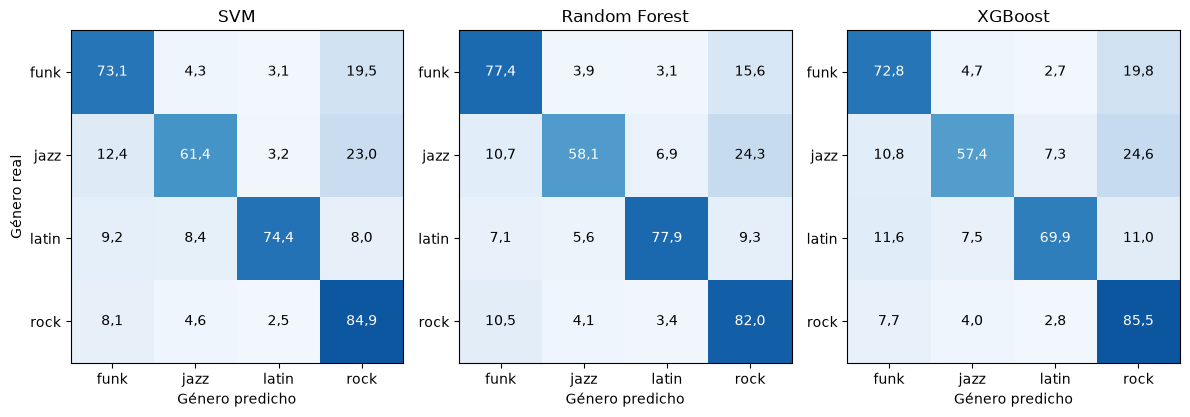

SVM
       funk  jazz  latin  rock
funk   73.1   4.3    3.1  19.5
jazz   12.4  61.4    3.2  23.0
latin   9.2   8.4   74.4   8.0
rock    8.1   4.6    2.5  84.9
Random Forest
       funk  jazz  latin  rock
funk   77.4   3.9    3.1  15.6
jazz   10.7  58.1    6.9  24.3
latin   7.1   5.6   77.9   9.3
rock   10.5   4.1    3.4  82.0
XGBoost
       funk  jazz  latin  rock
funk   72.8   4.7    2.7  19.8
jazz   10.8  57.4    7.3  24.6
latin  11.6   7.5   69.9  11.0
rock    7.7   4.0    2.8  85.5


In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

plt.style.use("default")
plt.rcParams["savefig.facecolor"] = "white"
FIGURES_DIR = RESULTS_DIR / "figures"

confusion_pct = {}
for name, preds in cv_preds.items():
    counts = sum(confusion_matrix(y_dev, preds[r], labels=GENRES) for r in preds.columns)
    confusion_pct[name] = 100 * counts / counts.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, (name, matrix) in zip(axes, confusion_pct.items()):
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=100)
    for i in range(len(GENRES)):
        for j in range(len(GENRES)):
            ax.text(j, i, f"{matrix[i, j]:.1f}".replace(".", ","), ha="center", va="center",
                    color="white" if matrix[i, j] > 50 else "black", fontsize=10)
    ax.set_title(name)
    ax.set_xticks(range(len(GENRES)), GENRES)
    ax.set_yticks(range(len(GENRES)), GENRES)
    ax.set_xlabel("Género predicho")
axes[0].set_ylabel("Género real")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_confusion_cv.png", dpi=300)
plt.show()

for name, matrix in confusion_pct.items():
    print(name)
    print(pd.DataFrame(matrix, index=GENRES, columns=GENRES).round(1).to_string())

## 4.4.3. Resultados por tipo de fragmento

No se entrena ni se predice nada nuevo: se reutilizan las predicciones de la validación cruzada del apartado 4.4.2 (`cv_preds`) y se separan según el tipo de fragmento de cada interpretación (*beat* o *fill*). Para cada tipo se calcula la macro-F1 en cada repetición, solo con las interpretaciones de ese tipo, y se hace la media de las 10 repeticiones.

### Tabla 23. Macro-F1 de los modelos principales en *beats* y en *fills*

In [6]:
TYPES = ["beat", "fill"]
beat_type = dev["beat_type"]

table_23 = pd.DataFrame({
    name: {
        bt: np.mean([f1_score(y_dev[beat_type == bt], preds.loc[beat_type == bt, r], average="macro")
                     for r in preds.columns])
        for bt in TYPES
    }
    for name, preds in cv_preds.items()
}).T.round(3)

print("Interpretaciones de cada tipo:", beat_type.value_counts().reindex(TYPES).to_dict())
print("Interpretaciones de cada género y tipo:")
print(pd.crosstab(dev["genre"], beat_type).to_string())
print()
print(table_23.to_string())

Interpretaciones de cada tipo: {'beat': 309, 'fill': 309}
Interpretaciones de cada género y tipo:
beat_type  beat  fill
genre                
funk         37   100
jazz         44    47
latin        45    42
rock        183   120

                beat   fill
SVM            0.748  0.736
Random Forest  0.718  0.752
XGBoost        0.696  0.740


### Confusión de jazz y funk con rock en cada tipo de fragmento

En el apartado 4.4.2, los errores más frecuentes eran asignar jazz y funk a rock. Se comprueba en qué tipo de fragmento se producen: porcentaje de interpretaciones de jazz y de funk asignadas a rock, en *beats* y en *fills* (suma de las 10 repeticiones).

In [7]:
rows = {}
for name, preds in cv_preds.items():
    for genre in ["jazz", "funk"]:
        for bt in TYPES:
            mask = (y_dev == genre) & (beat_type == bt)
            rows[(name, genre, bt)] = 100 * (preds.loc[mask] == "rock").to_numpy().mean()

to_rock = pd.Series(rows).unstack().round(1)
to_rock.index.names = ["modelo", "género real"]
print("Porcentaje asignado a rock:")
print(to_rock.to_string())

Porcentaje asignado a rock:
                           beat  fill
modelo        género real            
Random Forest funk         23.5  12.7
              jazz         34.3  14.9
SVM           funk         21.1  18.9
              jazz         33.6  13.0
XGBoost       funk         27.8  16.8
              jazz         36.1  13.8


## 4.4.4. Efecto del baterista y de la sesión de grabación

Se comprueba si los modelos reconocen el **género** o, en parte, la **sesión de grabación** (un baterista tocando en un mismo día y estudio). La sesión de cada interpretación es la parte de su `id` anterior al número final (por ejemplo, `drummer1/session1/12` → `drummer1/session1`).

### Tabla 24. Interpretaciones de cada género en las sesiones de entrenamiento y validación

Primero se mira cómo se reparten los géneros entre las sesiones. Se muestran las sesiones con más interpretaciones y, al final, qué porcentaje de cada género procede de la sesión más grande.

In [8]:
session = data.index.to_series().str.rsplit("/", n=1).str[0]
dev_session = session.loc[dev.index]

by_session = pd.crosstab(dev_session, y_dev).reindex(columns=GENRES)
by_session["total"] = by_session.sum(axis=1)
by_session = by_session.sort_values("total", ascending=False)
by_session.index.name = "sesión"
by_session.columns.name = None

largest = by_session.index[0]
print("Sesiones en entrenamiento y validación:", dev_session.nunique())
print(by_session.head(6).to_string())
print(f"\nPorcentaje de cada género que procede de {largest}:")
print((100 * by_session.loc[largest, GENRES] / by_session[GENRES].sum()).round(1).to_string())

Sesiones en entrenamiento y validación: 20
                   funk  jazz  latin  rock  total
sesión                                           
drummer1/session1    71    51     46    36    204
drummer7/session2     8     8      0    56     72
drummer7/session3    19     0      0    33     52
drummer3/session1     0    11      0    34     45
drummer1/session2    18     3      2    19     42
drummer3/session2     0     1      0    37     38

Porcentaje de cada género que procede de drummer1/session1:
funk     51.8
jazz     56.0
latin    52.9
rock     11.9


### Vecino más parecido de cada interpretación

Para cada una de las 618 interpretaciones se busca la interpretación más parecida (con las características estandarizadas, como hace k-NN) y se comprueba si es del mismo baterista y de la misma sesión, y si tiene el mismo género.

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

X_scaled = StandardScaler().fit_transform(X_dev)
_, neighbors = NearestNeighbors(n_neighbors=2).fit(X_scaled).kneighbors(X_scaled)
nearest = neighbors[:, 1]

same_drummer = dev["drummer"].to_numpy() == dev["drummer"].to_numpy()[nearest]
same_session = dev_session.to_numpy() == dev_session.to_numpy()[nearest]
same_genre = y_dev.to_numpy() == y_dev.to_numpy()[nearest]

print(f"Vecino del mismo baterista: {100 * same_drummer.mean():.1f} %")
print(f"Vecino de la misma sesión: {100 * same_session.mean():.1f} %")
print(f"Mismo género cuando el vecino es de la misma sesión: {100 * same_genre[same_session].mean():.1f} %")
print(f"Mismo género cuando el vecino es de otra sesión: {100 * same_genre[~same_session].mean():.1f} %")

Vecino del mismo baterista: 83.7 %
Vecino de la misma sesión: 73.9 %
Mismo género cuando el vecino es de la misma sesión: 85.1 %
Mismo género cuando el vecino es de otra sesión: 49.1 %


### Validación cruzada agrupada por sesión

Se repite la validación cruzada (5 grupos, 10 repeticiones) con la configuración elegida de cada modelo, pero poniendo **todas las interpretaciones de una sesión en el mismo grupo** (`grouped_cv_splits` en `src/models.py`). Así, el modelo siempre se evalúa con sesiones que no ha visto al entrenar. Se comparan k-NN y los tres modelos principales con su resultado en la validación cruzada normal (Tabla 20).

Advertencia: como varias sesiones reúnen muchas interpretaciones, los grupos quedan desiguales. Se muestra el tamaño y el reparto de géneros de los 5 grupos de la primera repetición.

In [10]:
from sklearn.model_selection import cross_val_score
from src.models import SCORING, grouped_cv_splits

group_splits = grouped_cv_splits(X_dev, y_dev, dev_session)
for k, (_, eval_idx) in enumerate(group_splits[:5]):
    print(f"Grupo {k + 1}: {len(eval_idx)} interpretaciones",
          y_dev.iloc[eval_idx].value_counts().reindex(GENRES, fill_value=0).to_dict())

SESSION_MODELS = ["k-NN", "SVM", "Random Forest", "XGBoost"]
grouped_scores = {}
for name in SESSION_MODELS:
    if name == "XGBoost":
        grouped_scores[name] = cross_val_score(
            models[name], X_dev, y_dev.map({g: i for i, g in enumerate(GENRES)}), cv=group_splits,
            scoring=SCORING, params={"model__sample_weight": compute_sample_weight("balanced", y_dev)}, n_jobs=-1)
    else:
        grouped_scores[name] = cross_val_score(models[name], X_dev, y_dev, cv=group_splits, scoring=SCORING, n_jobs=-1)

Grupo 1: 88 interpretaciones {'funk': 9, 'jazz': 8, 'latin': 11, 'rock': 60}
Grupo 2: 97 interpretaciones {'funk': 13, 'jazz': 6, 'latin': 16, 'rock': 62}
Grupo 3: 95 interpretaciones {'funk': 19, 'jazz': 12, 'latin': 3, 'rock': 61}
Grupo 4: 110 interpretaciones {'funk': 25, 'jazz': 14, 'latin': 11, 'rock': 60}
Grupo 5: 228 interpretaciones {'funk': 71, 'jazz': 51, 'latin': 46, 'rock': 60}


### Interpretaciones de prueba de sesiones vistas y no vistas

En la partición de prueba hay interpretaciones de sesiones que también están en entrenamiento y las de la sesión de evaluación del corpus (`eval_session`), que no aparece en entrenamiento. Se calcula la exactitud de cada modelo en cada caso con las predicciones del apartado 4.4.1. Solo se usa la exactitud porque las interpretaciones de la sesión de evaluación son únicamente de funk y rock.

In [11]:
test_session = session.loc[test.index]
seen = test_session.isin(dev_session).to_numpy()
print("Interpretaciones de prueba de sesiones vistas:", int(seen.sum()), "| de sesiones no vistas:", int((~seen).sum()),
      "| sesiones no vistas:", sorted(test_session[~seen].unique()))
print("Géneros de las no vistas:", y_test[~seen].value_counts().to_dict())

accuracy_seen = {name: (test_predictions[name] == y_test.to_numpy())[seen].mean() for name in SESSION_MODELS}
accuracy_unseen = {name: (test_predictions[name] == y_test.to_numpy())[~seen].mean() for name in SESSION_MODELS}

Interpretaciones de prueba de sesiones vistas: 53 | de sesiones no vistas: 16 | sesiones no vistas: ['drummer1/eval_session', 'drummer5/eval_session', 'drummer7/eval_session', 'drummer8/eval_session']
Géneros de las no vistas: {'funk': 12, 'rock': 4}


### Tabla 25. Rendimiento con sesiones vistas y no vistas durante el entrenamiento

Reúne los resultados anteriores: macro-F1 media en la validación cruzada normal y en la agrupada por sesión, y exactitud en la partición de prueba con sesiones vistas y no vistas.

In [12]:
table_25 = pd.DataFrame({
    "macro_f1_vc_normal": cv_scores[SESSION_MODELS].mean(),
    "macro_f1_vc_por_sesion": pd.Series({n: s.mean() for n, s in grouped_scores.items()}),
    "desv_vc_por_sesion": pd.Series({n: s.std() for n, s in grouped_scores.items()}),
    "exactitud_prueba_sesion_vista": pd.Series(accuracy_seen),
    "exactitud_prueba_sesion_no_vista": pd.Series(accuracy_unseen),
}).round(3)
print(table_25.to_string())

               macro_f1_vc_normal  macro_f1_vc_por_sesion  desv_vc_por_sesion  exactitud_prueba_sesion_vista  exactitud_prueba_sesion_no_vista
k-NN                        0.692                   0.399               0.079                          0.830                             0.375
SVM                         0.741                   0.417               0.132                          0.774                             0.500
Random Forest               0.739                   0.447               0.107                          0.717                             0.625
XGBoost                     0.723                   0.419               0.099                          0.679                             0.625


## 4.4.5. Importancia de las características

Mide **qué características usa cada modelo principal** para decidir el género, con la importancia por permutación (apartado 3.3.4):

1. Se entrena el modelo con 4 grupos y se calcula su macro-F1 en el grupo restante.
2. Se **desordenan al azar los valores de una característica** en ese grupo (las demás no se tocan) y se vuelve a calcular la macro-F1.
3. La **importancia** de la característica es cuánto baja la macro-F1. Si baja mucho, el modelo la necesita; si no baja, el modelo no la usa.

Cada característica se desordena 10 veces y se hace la media. Se usan las 5 rondas de la primera repetición de la validación cruzada (mismos grupos que en el apartado 4.3) y se promedian. Lo hace `cv_permutation_importance` en `src/models.py`.

Esta celda tarda alrededor de un minuto.

In [13]:
from src.models import cv_permutation_importance

importance = {}
for name in MAIN_MODELS:
    if name == "XGBoost":
        importance[name] = cv_permutation_importance(models[name], X_dev, y_dev, GENRES, numeric_labels=True,
                                                     sample_weight=compute_sample_weight("balanced", y_dev))
    else:
        importance[name] = cv_permutation_importance(models[name], X_dev, y_dev, GENRES)

importance = pd.DataFrame(importance)
importance.to_csv(RESULTS_DIR / "05_permutation_importance.csv", index_label="caracteristica")

for name in MAIN_MODELS:
    print(f"{name}: 10 características más importantes (bajada de la macro-F1)")
    print(importance[name].sort_values(ascending=False).head(10).round(3).to_string())
    print()

SVM: 10 características más importantes (bajada de la macro-F1)
density_kick      0.046
vel_mean          0.045
vel_snare_mean    0.039
density_total     0.035
vel_kick_range    0.029
vel_std           0.029
micro_mean        0.027
vel_snare_std     0.026
ioi_8th           0.023
ioi_triplet       0.020

Random Forest: 10 características más importantes (bajada de la macro-F1)
vel_mean                0.048
density_total           0.029
density_kick            0.024
micro_mean              0.022
density_snare           0.019
micro_std               0.017
density_tom_mid         0.016
vel_snare_mean          0.015
density_hihat_closed    0.014
vel_snare_std           0.014

XGBoost: 10 características más importantes (bajada de la macro-F1)
vel_mean            0.061
density_kick        0.040
micro_mean          0.038
density_total       0.030
vel_snare_mean      0.029
ioi_8th             0.024
share_crash         0.022
ioi_quarter_plus    0.021
share_snare         0.019
pos_16th_offbeat  

### Figura 8. Las diez características más importantes de cada modelo principal

Cada barra es la bajada media de la macro-F1 al desordenar esa característica. El color indica su grupo: actividad por pieza, distribución temporal o dinámica.

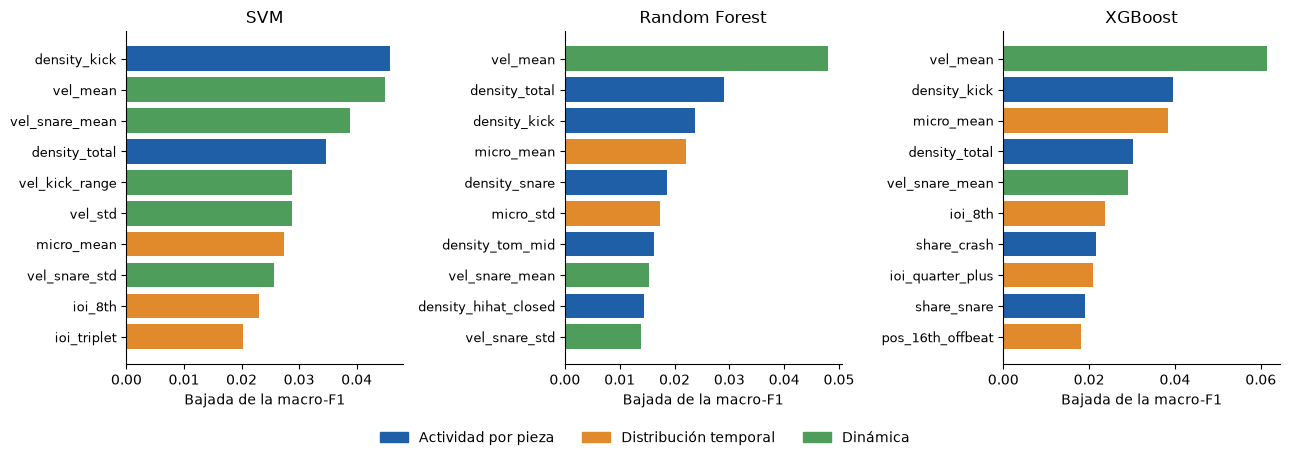

In [14]:
def feature_group(feature):
    if feature.startswith(("density_", "share_")):
        return "Actividad por pieza"
    if feature.startswith("vel_"):
        return "Dinámica"
    return "Distribución temporal"


GROUP_COLORS = {"Actividad por pieza": "#1f5fa8", "Distribución temporal": "#e08a2c", "Dinámica": "#4f9d5a"}

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, name in zip(axes, MAIN_MODELS):
    top = importance[name].sort_values().tail(10)
    ax.barh(top.index, top.values, color=[GROUP_COLORS[feature_group(f)] for f in top.index])
    ax.set_title(name)
    ax.set_xlabel("Bajada de la macro-F1")
    ax.tick_params(axis="y", labelsize=9)
    ax.spines[["top", "right"]].set_visible(False)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()],
           labels=list(GROUP_COLORS), loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIGURES_DIR / "fig_permutation_importance.png", dpi=300)
plt.show()

### Tabla 26. Importancia total de cada grupo de características

Suma de la importancia de las características de cada grupo, junto con el número de características del grupo. Un grupo con más características tiende a sumar más, por lo que esta tabla se complementa con el estudio de ablación del apartado 4.4.6.

In [15]:
groups = importance.index.map(feature_group)
table_26 = importance.groupby(groups).sum().round(3)
table_26.insert(0, "caracteristicas", pd.Series(groups).value_counts())
table_26 = table_26.loc[list(GROUP_COLORS)]
table_26.index.name = "grupo"
print(table_26.to_string())

                       caracteristicas    SVM  Random Forest  XGBoost
grupo                                                                
Actividad por pieza                 19  0.225          0.227    0.192
Distribución temporal               13  0.156          0.150    0.170
Dinámica                            12  0.251          0.151    0.150


## 4.4.6. Estudio de ablación por grupos de características

Mide **cuánto aporta cada grupo de características** (apartado 3.3.4). Para cada modelo principal, con su configuración elegida:

1. Se **quita un grupo entero** de características: las 19 de actividad por pieza, las 13 de distribución temporal o las 12 de dinámica.
2. Se **vuelve a entrenar y evaluar** el modelo con las características restantes, con las mismas 50 rondas de la validación cruzada del apartado 4.3.
3. Se compara su macro-F1 media con la del modelo con las 44 características (Tabla 20).

Si al quitar un grupo la macro-F1 baja mucho, ese grupo aporta información que los otros dos no tienen. Si apenas baja, su información está cubierta por los otros grupos.

A diferencia del apartado 4.4.5, aquí no se desordena nada: el grupo se elimina y el modelo aprende sin él.


In [16]:
from sklearn.model_selection import cross_val_score

FEATURE_GROUPS = {group: [f for f in FEATURES if feature_group(f) == group] for group in GROUP_COLORS}
print("Características por grupo:", {g: len(f) for g, f in FEATURE_GROUPS.items()})

ablation_scores = {}
for name in MAIN_MODELS:
    for group, removed in FEATURE_GROUPS.items():
        kept = [f for f in FEATURES if f not in removed]
        if name == "XGBoost":
            scores_ = cross_val_score(models[name], X_dev[kept], y_dev.map({g: i for i, g in enumerate(GENRES)}),
                                      cv=make_cv(), scoring=SCORING, n_jobs=-1,
                                      params={"model__sample_weight": compute_sample_weight("balanced", y_dev)})
        else:
            scores_ = cross_val_score(models[name], X_dev[kept], y_dev, cv=make_cv(), scoring=SCORING, n_jobs=-1)
        ablation_scores[(name, f"sin {group.lower()}")] = scores_
    print(name, "terminado")

ablation_scores = pd.DataFrame(ablation_scores)
ablation_scores.to_csv(RESULTS_DIR / "05_ablation_fold_scores.csv", index_label="ronda")

Características por grupo: {'Actividad por pieza': 19, 'Distribución temporal': 13, 'Dinámica': 12}
SVM terminado
Random Forest terminado
XGBoost terminado


### Tabla 27. Macro-F1 de los modelos principales al quitar cada grupo de características

Para cada modelo: macro-F1 media de las 50 rondas con las 44 características (Tabla 20) y sin cada grupo. Debajo, la diferencia respecto al modelo completo (valores negativos = el modelo empeora sin ese grupo).

In [17]:
table_27 = pd.DataFrame({"todas las características": cv_scores[MAIN_MODELS].mean()})
for (name, variant), values in ablation_scores.items():
    table_27.loc[name, variant] = values.mean()
table_27 = table_27.round(3)
print(table_27.to_string())

print("\nDiferencia respecto a todas las características:")
print(table_27.drop(columns="todas las características").sub(table_27["todas las características"], axis=0).round(3).to_string())

               todas las características  sin actividad por pieza  sin distribución temporal  sin dinámica
SVM                                0.741                    0.699                      0.696         0.654
Random Forest                      0.739                    0.683                      0.706         0.683
XGBoost                            0.723                    0.663                      0.680         0.645

Diferencia respecto a todas las características:
               sin actividad por pieza  sin distribución temporal  sin dinámica
SVM                             -0.042                     -0.045        -0.087
Random Forest                   -0.056                     -0.033        -0.056
XGBoost                         -0.060                     -0.043        -0.078


## 4.5. Comparación de resultados

### Contraste estadístico entre modelos


Se comparan los tres modelos principales entre sí, cada uno con k-NN (el mejor clasificador de referencia) y k-NN con la regresión logística.

### Tabla 28. Contraste estadístico entre pares de modelos

In [20]:
from src.models import corrected_ttest

COMPARISONS = [("SVM", "Random Forest"), ("SVM", "XGBoost"), ("Random Forest", "XGBoost"),
               ("SVM", "k-NN"), ("Random Forest", "k-NN"), ("XGBoost", "k-NN"),
               ("k-NN", "Regresión logística")]

rows = []
for a, b in COMPARISONS:
    diff, t, p = corrected_ttest(cv_scores[a], cv_scores[b])
    rows.append({"comparacion": f"{a} – {b}", "diferencia_media": round(diff, 3), "t": round(t, 2),
                 "p_valor": "< 0.001" if p < 0.001 else round(p, 3), "significativa": "sí" if p < 0.05 else "no"})

table_28 = pd.DataFrame(rows)
print(table_28.to_string(index=False))

               comparacion  diferencia_media    t  p_valor significativa
       SVM – Random Forest             0.002 0.09    0.927            no
             SVM – XGBoost             0.018 0.79    0.433            no
   Random Forest – XGBoost             0.017 1.01    0.319            no
                SVM – k-NN             0.049 1.94    0.058            no
      Random Forest – k-NN             0.048 1.84    0.071            no
            XGBoost – k-NN             0.031 1.05    0.299            no
k-NN – Regresión logística             0.099 3.45    0.001            sí


### Tabla 29. Resumen de los resultados de cada modelo

Reúne, para cada modelo, la macro-F1 de la validación cruzada (Tabla 20), la de la partición de prueba (Tabla 21) y la de la validación cruzada agrupada por sesión (Tabla 25).

In [19]:
table_29 = pd.DataFrame({
    "macro_f1_vc": cv_scores[MODEL_ORDER].mean(),
    "macro_f1_prueba": table_21["macro_f1"],
    "macro_f1_vc_por_sesion": pd.Series({n: s.mean() for n, s in grouped_scores.items()}),
}).loc[MODEL_ORDER[::-1]].round(3)
print(table_29.to_string(na_rep="—"))

                     macro_f1_vc  macro_f1_prueba  macro_f1_vc_por_sesion
XGBoost                    0.723            0.643                   0.419
Random Forest              0.739            0.658                   0.447
SVM                        0.741            0.675                   0.417
k-NN                       0.692            0.713                   0.399
Regresión logística        0.593            0.495                       —
Clase mayoritaria          0.164            0.155                       —
